# Write와 Select

**이 노트북에서 할 일**

1. 문서에서 옮겨 적은 기록 다섯 개를 JSON 파일에 쓰고 다시 읽습니다.
2. 기관과 주제 조건으로 질문에 필요한 기록만 골라, 01절 모양의 메시지 목록에 넣습니다.
3. 파일 이름만 적어 보낸 Before와, 고른 기록을 넣어 보낸 After의 답과 출처를 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 기록은 셀 안에 적고, 노트북이 임시 폴더에 파일로 씁니다.

인터넷 서비스에 요청을 모두 2번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3·4·6절(Write, Select, Before)을 설명합니다.
5·7절(값 바꿔 보기, After)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

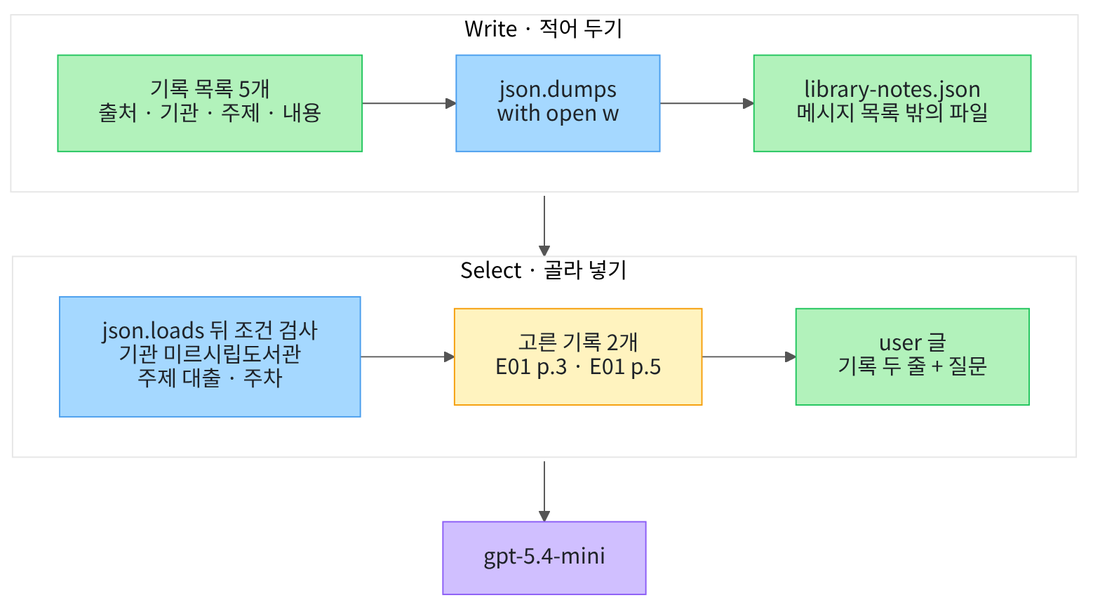

위 칸이 적어 두기(Write), 아래 칸이 골라 넣기(Select)입니다. 칸마다 왼쪽에서 오른쪽으로 읽고, 위 칸의 파일이 아래 칸으로 이어집니다.
초록 상자는 기록·파일·글이고, 파란 상자는 노트북 코드의 단계입니다. 노란 상자는 출력으로 확인한 고른 기록, 맨 아래 보라 상자는 모델입니다.
파일에 적어 둔 기록 다섯 개 가운데 두 개만 user 글에 들어가 모델로 갑니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

기록을 파일로 다루는 모듈과 01절에서 쓴 라이브러리를 불러오고, 01절에서 배운 함수 두 개를 가져옵니다.
모듈 `json`은 Ch 6 06절에서 기록을 파일에 쓸 때 썼습니다. 모듈 `os`와 `tempfile`은 Ch 2 05절 준비 셀에서 임시 폴더를 만들 때 썼습니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 01절 `input_budget()`·`count_tokens()`를 가져옵니다.

도구 파일의 `count_tokens()`는 토큰화 규칙 객체를 첫 인자로 받습니다. 01절 판은 함수 바깥 이름 `encoding`을 읽었습니다.

In [2]:
# 파일·폴더를 다루는 모듈과 토큰 수를 세는 라이브러리, 모델 함수를 불러옵니다
import json
import os
import tempfile

import tiktoken

from langchain.chat_models import init_chat_model
# 01절 함수 두 개를 도구 파일에서 가져옵니다
from llm_tools import count_tokens, input_budget

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


이 노트북은 기록 파일을 만들므로, 파일을 둘 빈 폴더를 먼저 준비합니다. Ch 2 05절 준비 셀과 같은 방법입니다.
함수 `tempfile.mkdtemp()`는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다.
함수 `os.chdir()`는 작업 폴더를 그 폴더로 옮깁니다. 그래서 실습 폴더에는 파일이 생기지 않습니다.

키 확인은 작업 폴더를 옮기기 전에 했습니다. `.env` 파일을 작업 폴더에서부터 찾기 때문입니다.

In [4]:
# 기록 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
work_folder = tempfile.mkdtemp(prefix="ch08-02-")
os.chdir(work_folder)
# listdir()는 현재 작업 폴더 안의 파일 이름 목록을 반환합니다
file_names = os.listdir()
print("작업 폴더의 파일:", file_names)

작업 폴더의 파일: []


**결과 읽기** — 출력 줄은 `작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.
폴더 경로는 실행할 때마다 달라서 출력하지 않았습니다.

## 2. 01절에서 이어 쓰는 글과 수업 예산표

01절의 페르소나와 과업 명세를 이어 씁니다. 페르소나는 글자까지 같습니다.
과업 명세는 출처를 적는 자리만 바꿨습니다. 이번 질문은 두 가지를 묻고 근거가 두 쪽에 있어, 출처를 문장마다 적게 했습니다.

In [5]:
# 01절에서 이어 쓰는 페르소나와, 출처를 문장마다 적게 한 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에 `문장마다 끝에 출처를`이 있습니다.
출처 표시 `[E01 p.2]`는 모양을 보여 주는 예입니다. 이 노트북의 기록에서 E01 2쪽은 휴관 기록입니다.

01절의 수업 예산표도 같은 값으로 이어 씁니다. 수업 예산 600에서 출력 예약분 120과 여유분 40을 먼저 뗍니다.
01절 용어 표에서 출력 예약분은 Ch 5 04절 출력 몫, Ch 6 01절 출력 상한과 같은 크기를 가리키는 이름이었습니다.

세 값을 01절과 같게 담고, 준비 셀에서 가져온 함수 `input_budget()`으로 입력 가용분을 구합니다.
실행 전에 예상합니다. 01절처럼 440일 것입니다.

In [6]:
# 01절과 같은 수업 예산·출력 예약분·여유분으로 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
고른 기록을 넣은 메시지 목록도 입력 가용분 440 안에 들어야 합니다.

요청 전에 토큰 수를 세려고 01절 5절처럼 토큰화 규칙 객체를 만듭니다.
함수 `tiktoken.encoding_for_model()`은 모델 이름을 받아 토큰화 규칙 객체를 반환합니다.
가져온 함수 `count_tokens()`에는 이 객체를 첫 인자로, 토큰 수를 셀 글을 둘째 인자로 넣습니다.

In [7]:
# 01절처럼 모델의 토큰화 규칙을 불러옵니다(가져온 count_tokens()에 첫 인자로 넣습니다)
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
print("토큰화 규칙 이름:", encoding.name)

토큰화 규칙 이름: o200k_base


**결과 읽기** — 출력 줄은 `토큰화 규칙 이름: o200k_base`로 01절과 같습니다.

모델 객체는 01절 After처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.
마지막 줄 `assert`는 예산표의 출력 예약분이 모델 설정에 그대로 들어갔는지 확인합니다.

In [8]:
# 출력 예약분을 출력 상한으로 준 모델을 준비합니다(01절 After와 같은 설정)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)
assert model.max_tokens == output_reserve

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): 120`입니다. `assert`도 통과했습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 3. Write — 기록을 파일에 적어 두기

이번 질문에 쓸 자료를 기록으로 만듭니다. 기록 하나는 사실 한 문장과, 그 사실을 설명하는 값 세 개를 담은 딕셔너리입니다.
키 `출처`는 문서 이름과 쪽, 키 `기관`은 문서를 낸 곳, 키 `주제`는 사람이 붙인 분류 이름입니다.
키 `내용`에는 원문을 읽고 사실 하나를 한 문장으로 옮겨 적었습니다. 원문 문단을 그대로 옮긴 글은 아닙니다.

Ch 9에서 쓰는 문서 모음에는 여러 기관의 문서가 함께 있습니다. 그래서 E01 미르시립도서관 기록 셋에 다른 기관 기록 둘을 더했습니다.
문서 E02는 별빛제과 신입사원 안내, 문서 E04는 청담해운 복지 안내입니다. 두 곳도 E01처럼 수업용 가상 기관입니다.
이 셀은 목록만 만들고 파일은 아직 쓰지 않습니다.

In [9]:
# 문서에서 옮겨 적은 기록 다섯 개를 목록으로 만듭니다(출처·기관·주제·내용)
records = [
    {"출처": "E01 p.2", "기관": "미르시립도서관", "주제": "휴관", "내용": "매주 월요일은 정기 휴관일입니다."},
    {"출처": "E01 p.3", "기관": "미르시립도서관", "주제": "대출", "내용": "도서는 7권까지 14일 동안 대출할 수 있습니다."},
    {"출처": "E01 p.5", "기관": "미르시립도서관", "주제": "주차", "내용": "회원은 최초 2시간 무료입니다."},
    {"출처": "E02 p.5", "기관": "별빛제과", "주제": "주차", "내용": "본사 주차장은 선착순이며 월 3만 원의 주차비가 급여에서 공제됩니다."},
    {"출처": "E04 p.2", "기관": "청담해운", "주제": "대출", "내용": "무주택 직원의 전세자금 대출 기간은 2년이며 2회 연장할 수 있습니다."},
]
print("기록 수:", len(records))
print("첫 기록:", records[0])

기록 수: 5
첫 기록: {'출처': 'E01 p.2', '기관': '미르시립도서관', '주제': '휴관', '내용': '매주 월요일은 정기 휴관일입니다.'}


**결과 읽기** — 출력 줄은 `기록 수: 5`와 `첫 기록:`으로 시작하는 한 줄입니다. 첫 기록의 출처는 `E01 p.2`, 주제는 `휴관`입니다.
딕셔너리를 출력하면 키와 값이 작은따옴표로 나옵니다. 기록은 아직 변수에만 있고, 파일도 메시지 목록도 아닙니다.

적어 두기(Write)는 나중에 쓸 정보를 이번 요청의 메시지 목록 밖에 저장해 두는 일입니다. 수업에서 들은 내용을 공책에 적어 두는 것과 비슷합니다.
이 노트북에서는 기록 목록을 JSON 글로 바꿔 파일 `library-notes.json`에 씁니다. Ch 6 06절에서 기록을 파일에 쓴 방법과 같습니다.

함수 `json.dumps()`는 목록을 JSON 글로 바꿉니다. 인자 `ensure_ascii=False`는 한글을 그대로 두고, 인자 `indent=2`는 줄을 나눠 읽기 좋게 합니다.
실행 전에 예상합니다. 작업 폴더에 파일 하나가 생길 것입니다.

In [10]:
# 기록 목록을 JSON 글로 바꿔 작업 폴더의 파일에 씁니다
notes_text = json.dumps(records, ensure_ascii=False, indent=2)
with open("library-notes.json", "w", encoding="utf-8") as file:
    file.write(notes_text)
file_names = os.listdir()
print("작업 폴더의 파일:", file_names)
print("파일에 쓴 글자 수:", len(notes_text))

작업 폴더의 파일: ['library-notes.json']
파일에 쓴 글자 수: 535


**결과 읽기** — 출력 줄은 `작업 폴더의 파일: ['library-notes.json']`과 `파일에 쓴 글자 수:` 줄입니다.
기록 다섯 개가 메시지 목록 밖의 파일에 저장됐습니다. 이 파일은 커널을 다시 시작해도 준비 셀이 만든 임시 폴더에 남습니다. 다시 실행하면 새 임시 폴더를 만들므로, 앞에서 쓴 파일은 읽지 않습니다.

파일을 다시 읽어 저장한 기록과 같은지 봅니다. 메서드 `read()`는 파일 글 전체를 반환합니다.
함수 `json.loads()`는 JSON 글을 받아 다시 목록으로 만듭니다. 실행 전에 예상합니다. 다시 읽은 목록은 처음 목록과 같을 것입니다.

In [11]:
# 파일을 다시 읽어 기록 목록으로 바꾸고, 처음 목록과 같은지 확인합니다
with open("library-notes.json", encoding="utf-8") as file:
    saved_text = file.read()
loaded = json.loads(saved_text)
print("다시 읽은 기록 수:", len(loaded))
same_records = loaded == records
print("처음 목록과 같은가:", same_records)
assert same_records

다시 읽은 기록 수: 5
처음 목록과 같은가: True


**결과 읽기** — 출력 줄은 `다시 읽은 기록 수: 5`와 `처음 목록과 같은가: True`입니다. `assert`도 통과했습니다.
파일에 적어 둔 기록은 언제든 다시 꺼내 쓸 수 있습니다. 하지만 01절에서 본 것처럼 목록에 넣지 않은 글은 이번 요청의 컨텍스트가 아닙니다.

## 4. Select — 질문에 필요한 기록만 골라 넣기

골라 넣기(Select)는 저장해 둔 정보 가운데 이번 질문에 필요한 것만 골라 메시지 목록에 넣는 일입니다.
시험 공부를 할 때 공책에서 그 과목 쪽만 펴는 것과 비슷합니다. 이 절에서는 사람이 조건을 코드에 적어 고릅니다.

질문은 미르시립도서관의 도서 대출 권수와 회원 주차 무료 시간을 묻습니다. 그래서 조건은 기관 하나와 주제 두 개입니다.
출처·기관·주제처럼 내용 옆에 적어 두고 고를 때 쓰는 값을 메타데이터(metadata)라고 부릅니다.
책 뒤표지의 출판사와 도서관 책등의 분류 번호처럼, 내용을 설명하는 값입니다.

In [12]:
# 질문과, 기록을 고를 조건(기관 하나·주제 두 개)을 정합니다
question_text = "미르시립도서관에서 도서는 몇 권까지 빌릴 수 있고, 회원 주차는 몇 시간 무료인가요?"
needed_institution = "미르시립도서관"
needed_topics = ["대출", "주차"]
print("질문:", question_text)
print("고를 기관:", needed_institution)
print("고를 주제:", needed_topics)

질문: 미르시립도서관에서 도서는 몇 권까지 빌릴 수 있고, 회원 주차는 몇 시간 무료인가요?
고를 기관: 미르시립도서관
고를 주제: ['대출', '주차']


**결과 읽기** — 출력 줄은 `질문:` 줄과 `고를 기관: 미르시립도서관`, `고를 주제: ['대출', '주차']`입니다.
조건은 질문을 읽은 사람이 정했습니다. 코드가 질문 글에서 조건을 뽑아낸 것이 아닙니다.

다시 읽은 기록을 하나씩 보며 두 조건을 검사합니다. 기관이 같고, 주제가 고를 주제 목록 안에 있는 기록만 목록 `selected`에 넣습니다.
두 조건을 `and`로 이었으므로 둘 다 참이어야 합니다.

목록에 대한 `in` 검사는 Ch 7 06절 허용 이름 검사와 같은 모양입니다.
실행 전에 예상합니다. 다섯 기록 가운데 E01 3쪽과 5쪽 기록 두 개가 골라질 것입니다.

In [13]:
# 기관이 같고 주제가 고를 주제 목록에 있는 기록만 고릅니다
selected = []
selected_sources = []
for note in loaded:
    same_institution = note["기관"] == needed_institution
    needed_topic = note["주제"] in needed_topics
    if same_institution and needed_topic:
        selected.append(note)
        selected_sources.append(note["출처"])
print("고른 기록 수:", len(selected))
print("고른 기록 출처:", selected_sources)

고른 기록 수: 2
고른 기록 출처: ['E01 p.3', 'E01 p.5']


**결과 읽기** — 출력 줄은 `고른 기록 수: 2`와 `고른 기록 출처: ['E01 p.3', 'E01 p.5']`입니다.
E01 2쪽의 휴관 기록은 주제가 달라 빠졌습니다. 별빛제과 주차 기록과 청담해운 대출 기록은 주제는 맞지만 기관이 달라 빠졌습니다.

고른 기록을 01절 근거 문단과 같은 모양으로 user 글에 옮깁니다. 줄마다 출처 표시를 대괄호에 넣어 앞에 붙입니다.
반복문 안에서는 Ch 7 03절처럼 같은 이름에 글을 `+`로 이어 다시 담습니다. 줄 끝의 `"\n"`은 줄바꿈입니다.
마지막에 빈 줄을 하나 더 두고 질문을 붙입니다.

In [14]:
# 고른 기록을 출처 표시와 함께 한 줄씩 이어, 근거와 질문이 든 user 글을 만듭니다
evidence_text = ""
for note in selected:
    line = "[" + note["출처"] + "] " + note["내용"]
    evidence_text = evidence_text + line + "\n"
user_text = evidence_text + "\n" + "질문: " + question_text
print("user 글:")
print(user_text)

user 글:
[E01 p.3] 도서는 7권까지 14일 동안 대출할 수 있습니다.
[E01 p.5] 회원은 최초 2시간 무료입니다.

질문: 미르시립도서관에서 도서는 몇 권까지 빌릴 수 있고, 회원 주차는 몇 시간 무료인가요?


**결과 읽기** — 라벨 줄 `user 글:` 아래 첫 줄은 `[E01 p.3] 도서는 7권까지 14일 동안 대출할 수 있습니다.`입니다.
둘째 줄은 `[E01 p.5] 회원은 최초 2시간 무료입니다.`이고, 빈 줄 다음에 `질문:` 줄이 있습니다.
파일에 있던 기록 다섯 개 가운데 두 개만 글로 옮겨졌습니다.

01절처럼 system 페르소나, developer 과업 명세, user 글로 메시지 목록을 만듭니다. 요청은 아직 보내지 않습니다.
01절 예산표처럼 세 글의 추정 입력을 세어 입력 가용분과 비교합니다.
실행 전에 예상합니다. 짧은 기록 두 줄이라 440 안에 들어갈 것입니다.

In [15]:
# Ch 7 모양의 메시지 목록을 만들고, 추정 입력을 입력 가용분과 비교합니다(요청은 보내지 않습니다)
messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", user_text),
]
estimated_input = count_tokens(encoding, persona_text) + count_tokens(encoding, task_text) + count_tokens(encoding, user_text)
fits = estimated_input <= available
print("메시지 수:", len(messages))
print("추정 입력 합계:", estimated_input)
print("입력 가용분 안에 드는가:", fits)
assert len(messages) == 3

메시지 수: 3
추정 입력 합계: 124
입력 가용분 안에 드는가: True


**결과 읽기** — 출력 줄은 `메시지 수: 3`, `추정 입력 합계: 124`, `입력 가용분 안에 드는가: True`입니다.
01절 3절 목록의 추정 187보다 작습니다. 이번 근거는 사실 한 문장씩 적은 기록 두 줄이기 때문입니다.
이 목록 `messages`는 7절 After에서 모델로 보냅니다.

## 5. 값 바꿔 보기 — 기관 조건을 빼면

바꾸는 값은 고르는 조건 하나입니다. 기관 조건을 빼고 주제만 봅니다. 질문과 기록 파일은 그대로 둡니다.
이 셀은 고르고 세기만 하고, 요청은 보내지 않습니다.

실행 전에 예상합니다. 주제가 대출이나 주차인 기록은 넷입니다. 다른 기관의 기록 두 개가 함께 골라질 것입니다.

In [16]:
# 기관 조건을 빼고 주제만으로 고른 뒤, 고른 기록 수와 근거 글의 토큰 수를 비교합니다
topic_only_sources = []
topic_only_text = ""
for note in loaded:
    if note["주제"] in needed_topics:
        topic_only_sources.append(note["출처"])
        line = "[" + note["출처"] + "] " + note["내용"]
        topic_only_text = topic_only_text + line + "\n"
print("주제만 본 기록 수:", len(topic_only_sources))
print("주제만 본 기록 출처:", topic_only_sources)
print("근거 토큰 수(기관 + 주제):", count_tokens(encoding, evidence_text))
print("근거 토큰 수(주제만):", count_tokens(encoding, topic_only_text))

주제만 본 기록 수: 4
주제만 본 기록 출처: ['E01 p.3', 'E01 p.5', 'E02 p.5', 'E04 p.2']
근거 토큰 수(기관 + 주제): 37
근거 토큰 수(주제만): 101


**결과 읽기** — 출력 줄은 `주제만 본 기록 수: 4`와 `주제만 본 기록 출처: ['E01 p.3', 'E01 p.5', 'E02 p.5', 'E04 p.2']`입니다.
근거 토큰 수는 `근거 토큰 수(기관 + 주제): 37`에서 `근거 토큰 수(주제만): 101`로 늘었습니다.

더해진 두 기록은 별빛제과 본사 주차비와 청담해운 전세자금 대출입니다. 주제 이름은 같지만, 질문한 도서관의 규칙이 아닙니다.
메타데이터 `기관`으로 고르지 않으면 이런 기록이 함께 들어갑니다. 이 목록을 보냈을 때 모델이 어느 기록을 쓰는지는 이번에 실행하지 않았습니다.

## 6. Before — 기록을 파일에만 두고, 메시지에는 파일 이름만 적기

적어 두기만 하고 골라 넣기를 빼먹은 경우를 봅니다. 기록은 파일에 있고, user 글에는 파일 이름과 질문만 적습니다.
파일에 저장했다고 알려 주면 모델이 그 파일을 읽을 것이라고 생각한 실수입니다. 이번 요청에는 파일을 여는 도구가 없습니다.

실행 전에 예상합니다. 메시지에 기록 내용이 없으니 답에 기록의 사실이 들어가지 않을 것입니다.

In [17]:
# 파일 이름만 적은 user 글로 메시지 목록을 만듭니다(이 셀은 요청을 보내지 않습니다)
before_user_text = "근거: library-notes.json 파일에 저장해 두었습니다." + "\n\n" + "질문: " + question_text
before_messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", before_user_text),
]
file_names = os.listdir()
print("작업 폴더의 파일:", file_names)
print("고른 기록이 user 글에 들어 있는가:", evidence_text in before_user_text)
before_estimate = count_tokens(encoding, persona_text) + count_tokens(encoding, task_text) + count_tokens(encoding, before_user_text)
print("추정 입력 합계:", before_estimate)

작업 폴더의 파일: ['library-notes.json']
고른 기록이 user 글에 들어 있는가: False
추정 입력 합계: 101


**결과 읽기** — 출력 줄은 `작업 폴더의 파일: ['library-notes.json']`과 `고른 기록이 user 글에 들어 있는가: False`입니다.
기록 파일은 작업 폴더에 있지만, 메시지 목록에 실린 것은 파일 이름 글자뿐입니다. 마지막 줄은 `추정 입력 합계: 101`입니다.

답을 받은 뒤 답에 적힌 출처 표시로 기록을 되짚어 보려고 함수를 하나 정의합니다. Ch 7 05절의 근거 대조를 코드로 돕는 함수입니다.
함수 `find_cited_notes()`는 답 글과 기록 목록을 받습니다. 출처 표시가 답 글에 들어 있는 기록만 목록으로 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [18]:
# 답 글에 출처 표시가 들어 있는 기록만 골라 반환하는 함수를 정의합니다
def find_cited_notes(answer_text, notes):
    cited = []
    for note in notes:
        mark = "[" + note["출처"] + "]"
        if mark in answer_text:
            cited.append(note)
    return cited

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

파일 이름만 적은 목록을 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.

In [19]:
# 파일 이름만 적은 목록을 보냅니다(요청 1번)
before_response = model.invoke(before_messages)
print("답:")
print(before_response.text)

답:
죄송하지만 현재 대화에는 `library-notes.json`의 내용이 제공되지 않아, 도서 대출 권수와 회원 주차 무료 시간을 확인할 수 없습니다. 근거 파일의 해당 내용을 보내주시면 두 문장 이내로 바로 답변드리겠습니다.


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `도서 대출 권수와 회원 주차 무료 시간을 확인할 수 없습니다.`로 끝납니다.
그 앞에서 `library-notes.json`의 내용이 대화에 제공되지 않았다고 했습니다. 둘째 문장은 `근거 파일의 해당 내용을 보내주시면`으로 시작합니다.

모델도 이번 메시지에 파일 내용이 없다고 답했습니다. 대출 권수 7권도, 주차 무료 2시간도 답에 없습니다.
답에는 출처 표시가 하나도 없고, 오류는 나지 않았습니다.

답의 토큰 수와 끝난 이유를 보고, 답에 적힌 출처 표시를 파일에서 다시 읽은 기록 다섯 개에서 찾습니다.
여러 기록이 나올 수 있어 라벨 줄을 따로 출력합니다.

In [20]:
# Before 답의 토큰 수와 끝난 이유를 보고, 답에 적힌 출처를 기록 목록에서 찾습니다
before_usage = before_response.usage_metadata
print("실제 입력 토큰 수:", before_usage["input_tokens"])
print("실제 출력 토큰 수:", before_usage["output_tokens"])
print("끝난 이유:", before_response.response_metadata["finish_reason"])
before_cited = find_cited_notes(before_response.text, loaded)
print("답의 출처 표시와 같은 기록:")
print(before_cited)

실제 입력 토큰 수: 115
실제 출력 토큰 수: 62
끝난 이유: stop
답의 출처 표시와 같은 기록:
[]


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 115`, `실제 출력 토큰 수: 62`, `끝난 이유: stop`입니다. 출력 상한 120에 닿기 전에 끝났습니다.
라벨 줄 `답의 출처 표시와 같은 기록:` 아래 목록은 `[]`로 비어 있습니다. 답에 출처 표시가 없었기 때문입니다.

파일에 적어 둔 기록은 메시지에 넣지 않으면 모델에 가지 않습니다. 모델은 파일 이름 글자만 받았고, 파일을 열 도구도 없었습니다.
이 결과는 질문 하나를 한 번 보낸 결과이고, 답 문장은 실행마다 달라질 수 있습니다.

## 7. After — 고른 기록을 user 글에 넣기

고치는 곳은 user 글 하나입니다. 파일을 읽어 조건으로 고른 기록 두 줄을 넣은 4절 목록 `messages`를 보냅니다.
페르소나·과업 명세·질문·모델 설정은 Before와 같습니다.

실행 전에 예상합니다. 답에 기록의 7권과 2시간이 나오고, 출처는 E01 3쪽과 5쪽일 것입니다.

In [21]:
# 고른 기록 두 줄이 든 4절 목록을 보냅니다(요청 1번)
after_response = model.invoke(messages)
print("답:")
print(after_response.text)

답:
도서는 7권까지 14일 동안 대출할 수 있습니다. [E01 p.3] 회원은 최초 2시간 무료입니다. [E01 p.5]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장 `도서는 7권까지 14일 동안 대출할 수 있습니다.` 끝에 `[E01 p.3]`이 붙었습니다.
둘째 문장 `회원은 최초 2시간 무료입니다.` 끝에는 `[E01 p.5]`가 붙었습니다. 두 문장 모두 user 글에 넣은 기록 문장과 글자가 같습니다.

Before 답에는 대출 권수도, 주차 시간도, 출처 표시도 없었습니다. After 답에서는 두 값과 출처 표시가 모두 넣은 기록과 이어집니다.

After 답의 토큰 수와 끝난 이유를 봅니다. 4절에서 센 추정 입력과 실제 입력의 차이도 01절처럼 여유분과 비교합니다.
마지막으로 답에 적힌 출처 표시를 기록 목록에서 찾습니다.

In [22]:
# After 답의 토큰 수·끝난 이유·추정과의 차이를 보고, 답에 적힌 출처를 기록 목록에서 찾습니다
after_usage = after_response.usage_metadata
print("실제 입력 토큰 수:", after_usage["input_tokens"])
print("실제 출력 토큰 수:", after_usage["output_tokens"])
print("끝난 이유:", after_response.response_metadata["finish_reason"])
input_gap = after_usage["input_tokens"] - estimated_input
print("실제 입력 - 추정 입력:", input_gap)
print("차이가 여유분 안에 드는가:", input_gap <= safety_margin)
after_cited = find_cited_notes(after_response.text, loaded)
print("답의 출처 표시와 같은 기록:")
print(after_cited)

실제 입력 토큰 수: 138
실제 출력 토큰 수: 42
끝난 이유: stop
실제 입력 - 추정 입력: 14
차이가 여유분 안에 드는가: True
답의 출처 표시와 같은 기록:
[{'출처': 'E01 p.3', '기관': '미르시립도서관', '주제': '대출', '내용': '도서는 7권까지 14일 동안 대출할 수 있습니다.'}, {'출처': 'E01 p.5', '기관': '미르시립도서관', '주제': '주차', '내용': '회원은 최초 2시간 무료입니다.'}]


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 138`, `실제 출력 토큰 수: 42`, `끝난 이유: stop`입니다.
그 아래 `실제 입력 - 추정 입력: 14`와 `차이가 여유분 안에 드는가: True`가 나왔습니다. 이번 목록에서도 01절처럼 차이가 14였습니다.

라벨 줄 `답의 출처 표시와 같은 기록:` 아래 목록에는 기록 두 개가 있습니다. 출처 `E01 p.3`의 대출 기록과 `E01 p.5`의 주차 기록으로, 4절에서 고른 두 기록입니다.
답의 출처 표시로 기록을 되짚으면 두 문장이 어느 기록에서 왔는지 확인할 수 있습니다.
기록은 원문을 한 문장으로 옮겨 적은 것입니다. 기록에 없는 조건은 출처가 가리키는 E01 원문의 그 쪽에서 확인합니다.

## 정리

- 기록 다섯 개를 파일에 적어 두고 다시 읽었지만, 파일에 있다는 것만으로는 이번 요청의 컨텍스트가 아니었습니다.
- 기관과 주제 조건으로 기록 두 개를 골라 user 글에 넣었습니다. 기관 조건을 빼자 다른 기관 기록 두 개가 함께 골라졌습니다.
- 파일 이름만 적은 Before 답은 파일 내용이 없어 확인할 수 없다고 했습니다. 고른 기록을 넣은 After 답은 기록의 7권·2시간과 출처 두 개를 적었습니다.

다음 03절에서는 고른 자료가 여전히 길 때 줄이는 방법과, 업무마다 메시지 목록을 나누는 방법을 다룹니다.